# Breast Cancer

In [2]:
!pip install pandas scikit-learn

In [3]:
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_wine
# Veriyi değişkene atıyorum
cancer_data = load_breast_cancer()

X_cancer = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y_cancer = cancer_data.target
# İstenildiği gibi özellik ve hedefi ayırdım.

# Çıktılar
print("Breast Cancer Dataset")
print(f"Dataset Shape: {X_cancer.shape}")

print("\nTarget Labels:", list(set(y_cancer)))
print("Target Names:", list(cancer_data.target_names))

print("\nNumber of samples in each class:")
class_counts = pd.Series(y_cancer).value_counts().sort_index()
for label, count in class_counts.items():
    print(f"Class {label} ({cancer_data.target_names[label]}): {count}")

print("\nFirst 5 Rows:")
display(X_cancer.head())


Breast Cancer Dataset
Dataset Shape: (569, 30)

Target Labels: [np.int64(0), np.int64(1)]
Target Names: [np.str_('malignant'), np.str_('benign')]

Number of samples in each class:
Class 0 (malignant): 212
Class 1 (benign): 357

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# 2. Dataset Quality Checks

In [4]:

print("Data Quality Report")

# Kopya satır sayısı
duplicates = X_cancer.duplicated().sum()
print(f"Duplicate Rows: {duplicates}")
if duplicates == 0:
    print("No duplicate rows found.")

# Eksik veri sayısı 
missing_values = X_cancer.isnull().sum()
total_missing = missing_values.sum()
print(f"\nTotal Missing Values: {total_missing}")
if total_missing == 0:
    print("No missing values present in any column.")

# IQR ile outliers bakalım
print("Potential Outliers IQR")
Q1= X_cancer.quantile(0.25)
Q3= X_cancer.quantile(0.75)
IQR = Q3 - Q1

# Alt ve üst sınırları belirledim
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Outliers olanları sayma
outliers_count = ((X_cancer < lower_bound) | (X_cancer > upper_bound)).sum()
print("Number of outliers:")
print(outliers_count)                 


# Veri tipleri özeti
numerical_features = X_cancer.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_cancer.select_dtypes(include=['object', 'category']).columns

print(f"\nFeature Data Types:")
print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")

print("\nDtypes of all features:")
print(X_cancer.dtypes.value_counts())

Data Quality Report
Duplicate Rows: 0
No duplicate rows found.

Total Missing Values: 0
No missing values present in any column.
Potential Outliers IQR
Number of outliers:
mean radius                14
mean texture                7
mean perimeter             13
mean area                  25
mean smoothness             6
mean compactness           16
mean concavity             18
mean concave points        10
mean symmetry              15
mean fractal dimension     15
radius error               38
texture error              20
perimeter error            38
area error                 65
smoothness error           30
compactness error          28
concavity error            22
concave points error       19
symmetry error             27
fractal dimension error    28
worst radius               17
worst texture               5
worst perimeter            15
worst area                 35
worst smoothness            7
worst compactness          16
worst concavity            12
worst concave poin

There are explicitly 0 missing values and 0 duplicate rows. All 30 features are numerical (float64), and there are no categorical features requiring encoding.

# 3. Exploratory Data Analysis

3.1 Descriptive Statistic


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



3.2 Class Distribution


C:\Users\Berkay\AppData\Local\Temp\ipykernel_23336\1414594290.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_cancer, palette='Set2')


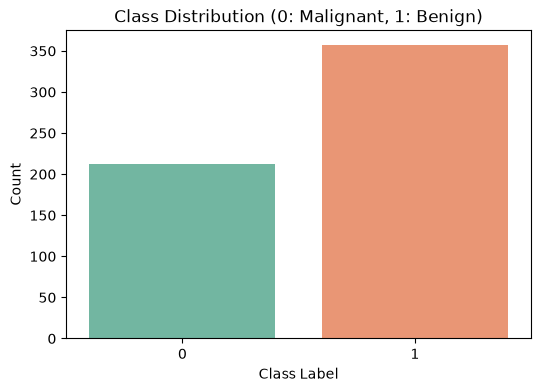


-3.2 Pearson Feature Correlation Heatmap


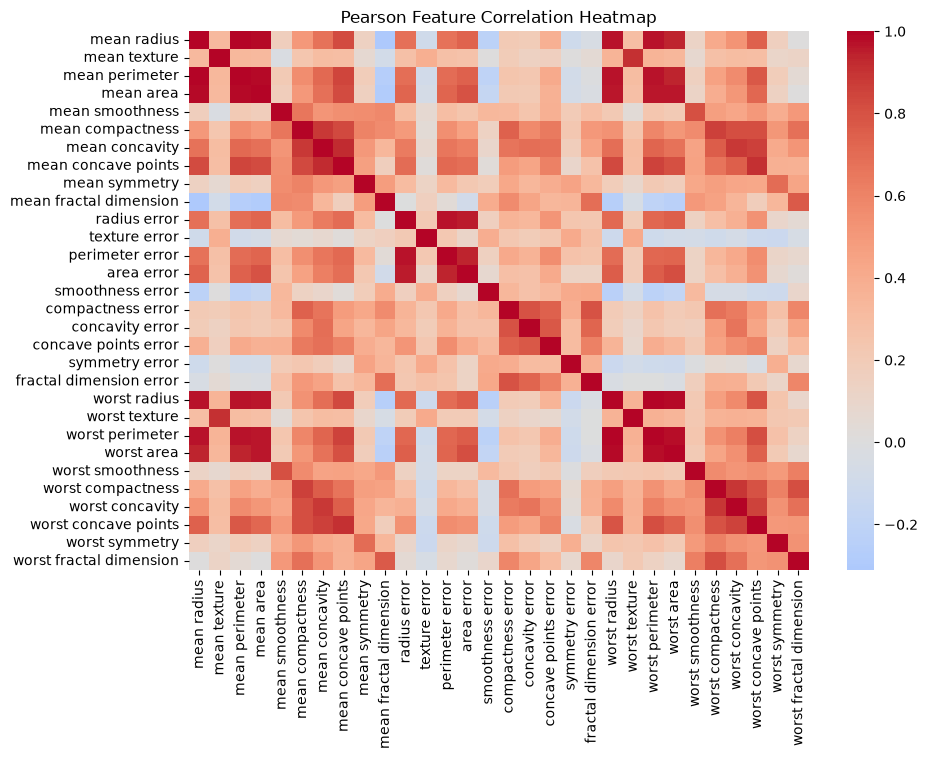


Top 3 Unique Feature Pairs by Absolute Correlation


mean perimeter  mean radius        0.997855
worst radius    worst perimeter    0.993708
mean radius     mean area          0.987357
dtype: float64


3.3 Boxplots


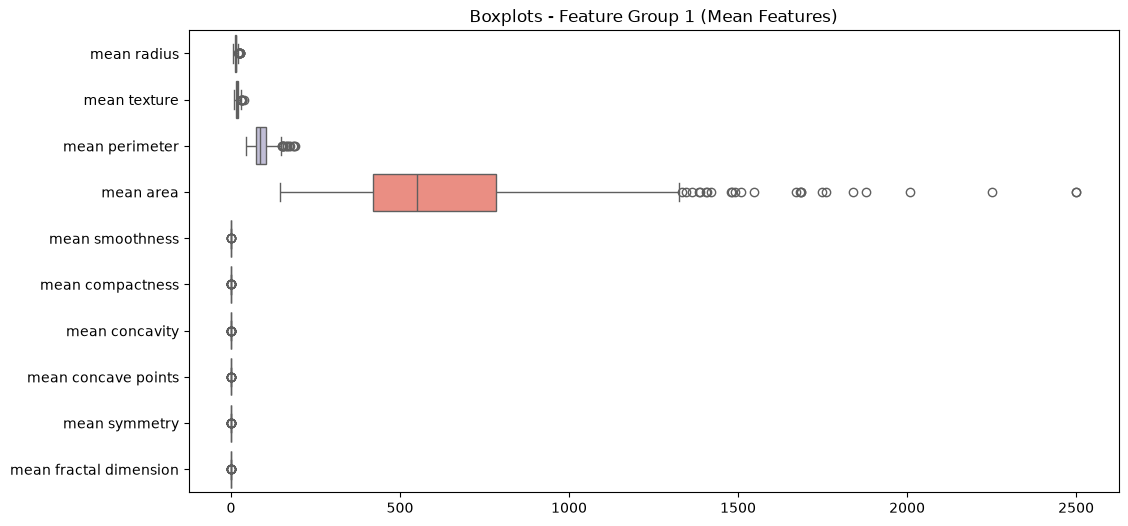

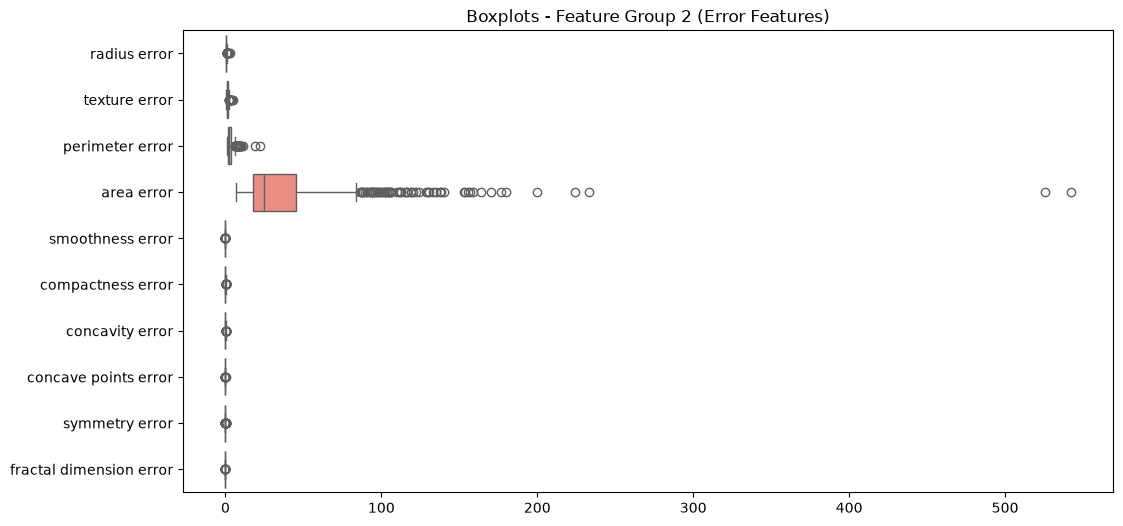

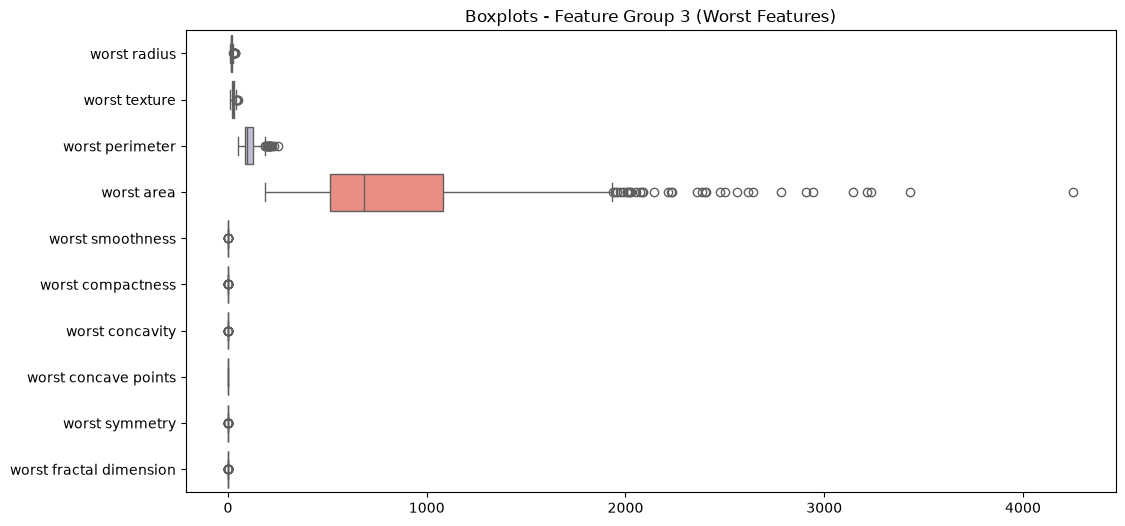

In [5]:
# Grafik kütüphanesi ekleme
!pip install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 3.1 Descriptive Statistics (Tanımlayıcı İstatistikler)

print("3.1 Descriptive Statistic")

display(X_cancer.describe().T) # .T ekrana sığması için transpose

# 3.2 Class Distribution and Correlations (Sınıf Dağılımı ve Korelasyonlar)

print("\n3.2 Class Distribution")
plt.figure(figsize=(6, 4))

# Sınıf dağılımını çubuk grafik ile çizdiriyorum
sns.countplot(x=y_cancer, palette='Set2')
plt.title('Class Distribution (0: Malignant, 1: Benign)')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.show()

print("\n-3.2 Pearson Feature Correlation Heatmap")
plt.figure(figsize=(10, 7))

# Pearson korelasyon matrisini hesaplıyorum
corr_matrix = X_cancer.corr(method='pearson')
# Isı haritasını çizdiriyoruz
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Pearson Feature Correlation Heatmap')
plt.show()

# En yüksek korelasyona sahip 3 eşsiz çift
print("\nTop 3 Unique Feature Pairs by Absolute Correlation")
# Matrisi düzleştirip mutlak değere göre büyükten küçüğe sıralıyorum
corr_pairs = corr_matrix.unstack().sort_values(key=abs, ascending=False)
# Kendisiyle olan (%100) eşleşmeleri ve simetrik görüntüleri çıkarıyorum
corr_pairs = corr_pairs[corr_pairs != 1.0].drop_duplicates()
display(corr_pairs.head(3))


# 3.3 Boxplots (Kutu Grafikleri)

print("\n3.3 Boxplots")

# 30 özelliği daha rahat okuyabilmek için 10'arlı 3 gruba ayırıyorum
features_group1 = X_cancer.columns[:10]
features_group2 = X_cancer.columns[10:20]
features_group3 = X_cancer.columns[20:]

# 1. Grup Grafiği
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_cancer[features_group1], orient='h', palette='Set3')
plt.title('Boxplots - Feature Group 1 (Mean Features)')
plt.show()

# 2. Grup Grafiği
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_cancer[features_group2], orient='h', palette='Set3')
plt.title('Boxplots - Feature Group 2 (Error Features)')
plt.show()

# 3. Grup Grafiği
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_cancer[features_group3], orient='h', palette='Set3')
plt.title('Boxplots - Feature Group 3 (Worst Features)')
plt.show()

The features have very different sizes and ranges. Because of this, we must scale the data before using the KNN model. The boxplots show some very big numbers (outliers), but we did not delete them because they are real data. We also found the top three correlated features using the heatmap.

# 4. Splitting Dataset

In [6]:

#Splitting the Dataset

print("Splitting the Datasets")

from sklearn.model_selection import train_test_split
import pandas as pd

SEEDS = [42, 52, 62]
total_samples = len(X_cancer)

# 1- Test setini tek seferde ayırıp kilitliyoruz (test_size=0.20, random_state=42)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_cancer, y_cancer, test_size=0.20, stratify=y_cancer, random_state=42
)

# Her seed için bölünen verileri saklayacağımız dictionaryler
X_train_dict = {}
X_val_dict = {}
y_train_dict = {}
y_val_dict = {}

# Raporlama tablosu için boş liste
split_summary = []

# 2- Kalan %80'lik kısmı (X_temp), her bir seed için eğitim (%70) ve doğrulama (%10) olarak bölüyoruz
for seed in SEEDS:
    # 0.125 * 0.80 = 0.10 (Tüm verinin %10'u validation olacak)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed
    )
    
    # Verileri seed anahtarıyla sözlüklere kaydediyoruz (Orijinal indeksleri bozulmuyor)
    X_train_dict[seed] = X_train
    X_val_dict[seed] = X_val
    y_train_dict[seed] = y_train
    y_val_dict[seed] = y_val
    
    # Sınıf dağılımlarını hesaplıyoruz (Malignant=0, Benign=1)
    train_counts = pd.Series(y_train).value_counts().to_dict()
    val_counts = pd.Series(y_val).value_counts().to_dict()
    test_counts = pd.Series(y_test).value_counts().to_dict()
    
    # Tabloya satırları ekliyoruz
    split_summary.append({
        'Seed': seed, 'Subset': 'Train', 'Total Samples': len(X_train),
        'Percentage': f"{(len(X_train)/total_samples)*100:.1f}%",
        'Class 0 (Malignant)': train_counts.get(0, 0), 'Class 1 (Benign)': train_counts.get(1, 0)
    })
    split_summary.append({
        'Seed': seed, 'Subset': 'Validation', 'Total Samples': len(X_val),
        'Percentage': f"{(len(X_val)/total_samples)*100:.1f}%",
        'Class 0 (Malignant)': val_counts.get(0, 0), 'Class 1 (Benign)': val_counts.get(1, 0)
    })
    split_summary.append({
        'Seed': seed, 'Subset': 'Test', 'Total Samples': len(X_test),
        'Percentage': f"{(len(X_test)/total_samples)*100:.1f}%",
        'Class 0 (Malignant)': test_counts.get(0, 0), 'Class 1 (Benign)': test_counts.get(1, 0)
    })

# 3- 9 satırlık özel tablo
df_split_summary = pd.DataFrame(split_summary)
display(df_split_summary)

print("\n Verifying Row Indices (Test indekslerinin değişmediğinin kanıtı)")
print(f"Test indices for seed 42 (first 5): {X_test.index[:5].tolist()}")
# Test seti sabit olduğu için seed 42'nin test indeksi ile diğerlerini kıyaslamaya gerek yok,
# ama train/val indekslerinin korunduğunu gösterelim:
print(f"Train indices for seed 42 (first 5): {X_train_dict[42].index[:5].tolist()}")
print(f"Train indices for seed 52 (first 5): {X_train_dict[52].index[:5].tolist()}")
print(f"Train indices for seed 62 (first 5): {X_train_dict[62].index[:5].tolist()}")

Splitting the Datasets


,Seed,Subset,Total Samples,Percentage,Class 0 (Malignant),Class 1 (Benign)
0,42,Train,398,69.9%,149,249
1,42,Validation,57,10.0%,21,36
2,42,Test,114,20.0%,42,72
3,52,Train,398,69.9%,149,249
4,52,Validation,57,10.0%,21,36
5,52,Test,114,20.0%,42,72
6,62,Train,398,69.9%,149,249
7,62,Validation,57,10.0%,21,36
8,62,Test,114,20.0%,42,72



 Verifying Row Indices (Test indekslerinin değişmediğinin kanıtı)
Test indices for seed 42 (first 5): [256, 428, 501, 363, 564]
Train indices for seed 42 (first 5): [301, 390, 420, 356, 446]
Train indices for seed 52 (first 5): [427, 81, 294, 47, 12]
Train indices for seed 62 (first 5): [3, 508, 471, 379, 319]


We saved 20% of the data as a test set and locked it with seed 42. We split the rest of the data into training (70%) and validation (10%) for three different seeds. We used "stratify" so all groups have the same class balance. The table shows that our splitting is completely correct and safe.

# 5.Data Preprocessing and Scaling

In [7]:

# 5. Data Preprocessing and Scaling

print("Preprocessing and Scaling")

from sklearn.preprocessing import StandardScaler
import pandas as pd

# 5.1
print("Step 5.1: No missing values exist in the dataset, so no imputation step is added.")

X_train_scaled_dict = {}
X_val_scaled_dict = {}
X_test_scaled = None  # Test setini dictionary yapmıyoruz, tek bir değişken olacak

for seed in SEEDS:
    # Scaler'ı oluşturuyoruz
    scaler = StandardScaler()
    
    # Sadece train verisinden öğren (fit) ve onu dönüştür (transform)
    X_train_scaled_dict[seed] = pd.DataFrame(
        scaler.fit_transform(X_train_dict[seed]), 
        columns=X_train_dict[seed].columns, 
        index=X_train_dict[seed].index
    )
    
    # Train'den öğrendiğin şablonla Validation verisini SADECE dönüştür (transform)
    X_val_scaled_dict[seed] = pd.DataFrame(
        scaler.transform(X_val_dict[seed]), 
        columns=X_val_dict[seed].columns, 
        index=X_val_dict[seed].index
    )
    
    # KURAL: Test setini sadece seed 42'nin scaler'ı ile dönüştür
    if seed == 42:
        X_test_scaled = pd.DataFrame(
            scaler.transform(X_test), 
            columns=X_test.columns, 
            index=X_test.index
        )

print("\nStep 5.3: Scaling completed correctly without data leakage!\n")

# KURAL: Seed 42 için tüm özelliklerin ilk 5 satırını göster
print("--- Before Scaling (Seed 42) First 5 Training Rows ---")
display(X_train_dict[42].head(5))

print("\n--- After Scaling (Seed 42) First 5 Training Rows ---")
display(X_train_scaled_dict[42].head(5))

Preprocessing and Scaling
Step 5.1: No missing values exist in the dataset, so no imputation step is added.

Step 5.3: Scaling completed correctly without data leakage!

--- Before Scaling (Seed 42) First 5 Training Rows ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075



--- After Scaling (Seed 42) First 5 Training Rows ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


There are no missing values in the dataset. We used StandardScaler to make all numbers similar in size, and it only learned from the training data to stop data leakage. We then changed the validation sets, and we only used the seed 42 scaler for the test set.

# 6. Preparing the Two Data Representations

In [8]:

print("6. Preparing the Two Data Representations")

# Verilerimiz önceki adımlarda zaten hazırlandı. Sadece teyit ediyoruz:
# 1. Unscaled (Ölçeklenmemiş) Veriler: X_train_dict, X_val_dict
# 2. Scaled (Ölçeklenmiş) Veriler: X_train_scaled_dict, X_val_scaled_dict

print("Representation 1: Unscaled data is ready for all seeds.")
print("Representation 2: Scaled data is ready for all seeds.")
print("No features were removed and row indices match perfectly across both representations.")

6. Preparing the Two Data Representations
Representation 1: Unscaled data is ready for all seeds.
Representation 2: Scaled data is ready for all seeds.
No features were removed and row indices match perfectly across both representations.


# 7. Training the Classification Models

In [9]:
# ---------------------------------------------------------
# 7. Training the Classification Models & 8. Validation
# ---------------------------------------------------------
print("--- 7. Training Models & 8. Validation (Breast Cancer) ---")

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Tüm koşuların sonuçlarını tutacağımız ana liste
classifier_runs = []

# Test seti (Bölüm 9) için sadece seed 42 modellerini saklayacağımız kasa
saved_models_seed42 = {}

# Modellerin ayarları
dt_depths = [2, 3, 5, 10, None]
knn_neighbors = [1, 3, 5, 7, 11]
representations = ['unscaled', 'scaled']
dataset_name = 'breast_cancer'

for seed in SEEDS:
    for rep in representations:
        # Hangi veriyi kullanacağımızı seçiyoruz
        if rep == 'unscaled':
            X_tr = X_train_dict[seed]
            X_v = X_val_dict[seed]
        else:
            X_tr = X_train_scaled_dict[seed]
            X_v = X_val_scaled_dict[seed]
            
        y_tr = y_train_dict[seed]
        y_v = y_val_dict[seed]

        # --------------------------------------------------
        # 1. DECISION TREE (Karar Ağacı)
        # --------------------------------------------------
        for depth in dt_depths:
            # Run ID oluşturma
            param_str = f"d{depth}" if depth is not None else "dNone"
            run_id = f"{dataset_name}_dt_{rep}_{param_str}_s{seed}"
            
            # Modeli kur ve eğit (Decision Tree için random_state=seed kuralı var)
            model = DecisionTreeClassifier(max_depth=depth, random_state=seed)
            model.fit(X_tr, y_tr)
            
            # Seed 42 ise modeli kasaya kaydet
            if seed == 42:
                saved_models_seed42[f"dt_{rep}_{param_str}"] = model
                
            # Eğitim Metrikleri
            y_tr_pred = model.predict(X_tr)
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro')
            
            # Doğrulama (Validation) Metrikleri (Bölüm 8 Kuralları)
            y_v_pred = model.predict(X_v)
            val_acc = accuracy_score(y_v, y_v_pred)
            val_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
            
            # ROC-AUC (Breast Cancer: Malignant=0 pozitif sınıf kabul edilecek kuralı)
            y_v_prob = model.predict_proba(X_v)[:, 0] # Sınıf 0'ın (Malignant) olasılığı
            y_v_binary = (y_v == 0).astype(int) # Gerçek değerleri 0 ise 1, 1 ise 0 yap
            val_roc = roc_auc_score(y_v_binary, y_v_prob)
            
            # Sonuçları listeye ekle
            classifier_runs.append({
                'Run_ID': run_id, 'Dataset': dataset_name, 'Algorithm': 'Decision Tree',
                'Representation': rep, 'Parameter': str(depth), 'Seed': seed,
                'Train_Accuracy': train_acc, 'Train_Macro_F1': train_f1,
                'Val_Accuracy': val_acc, 'Val_Macro_Precision': val_prec,
                'Val_Macro_Recall': val_rec, 'Val_Macro_F1': val_f1, 'Val_ROC_AUC': val_roc
            })

        # --------------------------------------------------
        # 2. K-NEAREST NEIGHBORS (KNN)
        # --------------------------------------------------
        for k in knn_neighbors:
            run_id = f"{dataset_name}_knn_{rep}_k{k}_s{seed}"
            
            model = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            model.fit(X_tr, y_tr)
            
            if seed == 42:
                saved_models_seed42[f"knn_{rep}_k{k}"] = model
                
            y_tr_pred = model.predict(X_tr)
            train_acc = accuracy_score(y_tr, y_tr_pred)
            train_f1 = f1_score(y_tr, y_tr_pred, average='macro')
            
            y_v_pred = model.predict(X_v)
            val_acc = accuracy_score(y_v, y_v_pred)
            val_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
            val_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
            
            y_v_prob = model.predict_proba(X_v)[:, 0]
            y_v_binary = (y_v == 0).astype(int)
            val_roc = roc_auc_score(y_v_binary, y_v_prob)
            
            classifier_runs.append({
                'Run_ID': run_id, 'Dataset': dataset_name, 'Algorithm': 'KNN',
                'Representation': rep, 'Parameter': str(k), 'Seed': seed,
                'Train_Accuracy': train_acc, 'Train_Macro_F1': train_f1,
                'Val_Accuracy': val_acc, 'Val_Macro_Precision': val_prec,
                'Val_Macro_Recall': val_rec, 'Val_Macro_F1': val_f1, 'Val_ROC_AUC': val_roc
            })

        # --------------------------------------------------
        # 3. GAUSSIAN NAIVE BAYES (GNB)
        # --------------------------------------------------
        run_id = f"{dataset_name}_gnb_{rep}_default_s{seed}"
        
        model = GaussianNB()
        model.fit(X_tr, y_tr)
        
        if seed == 42:
            saved_models_seed42[f"gnb_{rep}_default"] = model
            
        y_tr_pred = model.predict(X_tr)
        train_acc = accuracy_score(y_tr, y_tr_pred)
        train_f1 = f1_score(y_tr, y_tr_pred, average='macro')
        
        y_v_pred = model.predict(X_v)
        val_acc = accuracy_score(y_v, y_v_pred)
        val_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
        val_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
        val_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
        
        y_v_prob = model.predict_proba(X_v)[:, 0]
        y_v_binary = (y_v == 0).astype(int)
        val_roc = roc_auc_score(y_v_binary, y_v_prob)
        
        classifier_runs.append({
            'Run_ID': run_id, 'Dataset': dataset_name, 'Algorithm': 'GaussianNB',
            'Representation': rep, 'Parameter': 'default', 'Seed': seed,
            'Train_Accuracy': train_acc, 'Train_Macro_F1': train_f1,
            'Val_Accuracy': val_acc, 'Val_Macro_Precision': val_prec,
            'Val_Macro_Recall': val_rec, 'Val_Macro_F1': val_f1, 'Val_ROC_AUC': val_roc
        })

# Tüm sonuçları Dataframe'e çevirip boyutunu kontrol edelim (Hocanın kuralı: Tam 66 satır olmalı)
df_classifier_runs = pd.DataFrame(classifier_runs)
print(f"Total runs executed successfully: {len(df_classifier_runs)} (Expected: 66)")
display(df_classifier_runs.head(66))

--- 7. Training Models & 8. Validation (Breast Cancer) ---
Total runs executed successfully: 66 (Expected: 66)


,Run_ID,Dataset,Algorithm,Representation,Parameter,Seed,Train_Accuracy,Train_Macro_F1,Val_Accuracy,Val_Macro_Precision,Val_Macro_Recall,Val_Macro_F1,Val_ROC_AUC
0,breast_cancer_dt_unscaled_d2_s42,breast_cancer,Decision Tree,unscaled,2,42,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661
1,breast_cancer_dt_unscaled_d3_s42,breast_cancer,Decision Tree,unscaled,3,42,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312
2,breast_cancer_dt_unscaled_d5_s42,breast_cancer,Decision Tree,unscaled,5,42,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296
3,breast_cancer_dt_unscaled_d10_s42,breast_cancer,Decision Tree,unscaled,10,42,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
4,breast_cancer_dt_unscaled_dNone_s42,breast_cancer,Decision Tree,unscaled,None,42,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,breast_cancer_knn_scaled_k3_s62,breast_cancer,KNN,scaled,3,62,0.984925,0.983820,0.982456,0.986486,0.976190,0.980956,0.997354
62,breast_cancer_knn_scaled_k5_s62,breast_cancer,KNN,scaled,5,62,0.972362,0.970294,0.982456,0.986486,0.976190,0.980956,0.999339
63,breast_cancer_knn_scaled_k7_s62,breast_cancer,KNN,scaled,7,62,0.969849,0.967453,1.000000,1.000000,1.000000,1.000000,1.000000
64,breast_cancer_knn_scaled_k11_s62,breast_cancer,KNN,scaled,11,62,0.972362,0.970209,1.000000,1.000000,1.000000,1.000000,1.000000


We trained Decision Tree, KNN, and Naive Bayes models using our training data. We successfully ran 66 tests for both scaled and unscaled data across three different seeds. Finally, we safely saved only the seed 42 models for our final test later.

# 8. Measuring Validation Performance

--- 8.2 Comparison Tables & Model Selection ---
🏆 SELECTED CHAMPION MODEL FOR BREAST CANCER 🏆
Algorithm: KNN
Representation: scaled
Parameter: 7
Validation Macro-F1 (Mean): 0.9677

Summary table shape: 22 rows (Expected: 22)


,Algorithm,Representation,Parameter,Train_Accuracy_mean,Train_Accuracy_std,Train_Macro_F1_mean,Train_Macro_F1_std,Val_Accuracy_mean,Val_Accuracy_std,Val_Macro_Precision_mean,Val_Macro_Precision_std,Val_Macro_Recall_mean,Val_Macro_Recall_std,Val_Macro_F1_mean,Val_Macro_F1_std,Val_ROC_AUC_mean,Val_ROC_AUC_std,Config_ID
0,KNN,scaled,7,0.972362,0.002513,0.970234,0.002752,0.970760,0.026799,0.978408,0.019661,0.960317,0.036370,0.967675,0.029718,0.978175,0.019384,KNN_scaled_7
1,KNN,scaled,11,0.971524,0.001451,0.969381,0.001509,0.964912,0.035088,0.974561,0.025012,0.952381,0.047619,0.960846,0.039478,0.994489,0.004785,KNN_scaled_11
2,KNN,scaled,3,0.980737,0.003838,0.979314,0.004134,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979277,0.016151,KNN_scaled_3
3,KNN,scaled,5,0.974037,0.002901,0.972117,0.003158,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979497,0.017386,KNN_scaled_5
4,KNN,scaled,1,1.000000,0.000000,1.000000,0.000000,0.941520,0.020258,0.940964,0.028337,0.933862,0.016038,0.936898,0.021295,0.933862,0.016038,KNN_scaled_1
5,GaussianNB,unscaled,default,0.937186,0.004352,0.932282,0.004872,0.941520,0.020258,0.938445,0.016375,0.937169,0.030759,0.936854,0.022646,0.979718,0.012572,GaussianNB_unscaled_default
6,GaussianNB,scaled,default,0.935511,0.005230,0.930676,0.005764,0.929825,0.017544,0.923854,0.014035,0.927910,0.028912,0.924770,0.020075,0.975970,0.014941,GaussianNB_scaled_default
7,Decision Tree,scaled,10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,Decision Tree_scaled_10
8,Decision Tree,scaled,None,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,Decision Tree_scaled_None
9,Decision Tree,unscaled,10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952,Decision Tree_unscaled_10


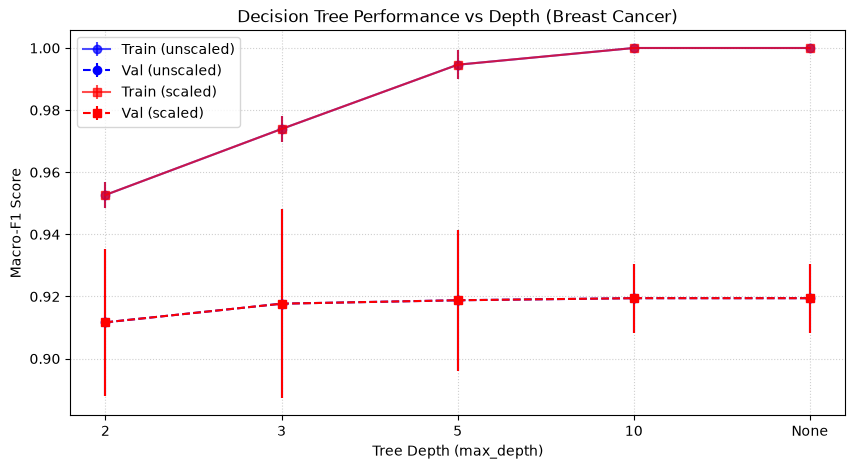

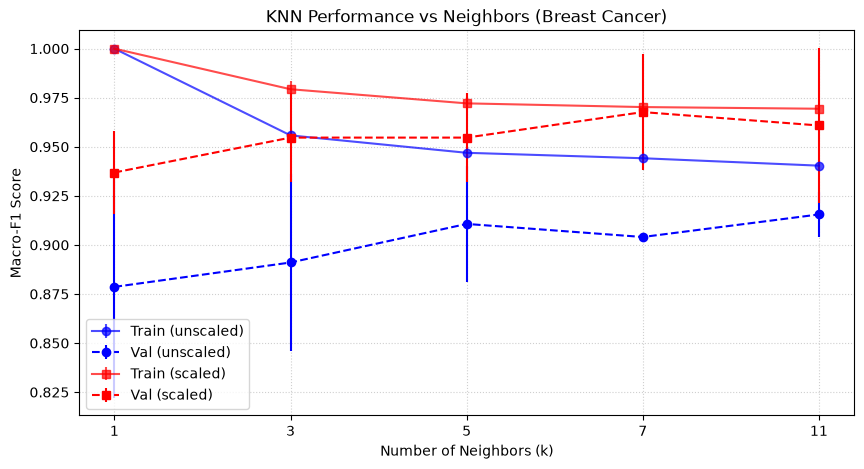

In [10]:
# ---------------------------------------------------------
# 8.2 Comparison Tables and Model Selection (Breast Cancer)
# ---------------------------------------------------------
print("--- 8.2 Comparison Tables & Model Selection ---")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. ÖZET TABLOYU OLUŞTURMA (Her kombinasyonun 3 seed ortalaması ve sapması)
groupby_cols = ['Algorithm', 'Representation', 'Parameter']
numeric_cols = [
    'Train_Accuracy', 'Train_Macro_F1', 'Val_Accuracy', 
    'Val_Macro_Precision', 'Val_Macro_Recall', 'Val_Macro_F1', 'Val_ROC_AUC'
]

# Pandas agg fonksiyonunda 'std' varsayılan olarak ddof=1 kullanır 
df_summary = df_classifier_runs.groupby(groupby_cols)[numeric_cols].agg(['mean', 'std']).reset_index()

# Sütun isimlerini düzeltme (Örn: Val_Macro_F1_mean, Val_Macro_F1_std)
df_summary.columns = ['_'.join(col).strip('_') for col in df_summary.columns.values]

# Şampiyon seçimi için eşitlik bozma (Tie-breaking) kuralına uygun ID oluşturma
df_summary['Config_ID'] = df_summary['Algorithm'] + "_" + df_summary['Representation'] + "_" + df_summary['Parameter']

# 2. ŞAMPİYON MODELİ SEÇME
# Kural: 1. Max F1 -> 2. Max Acc -> 3. Min F1 Std -> 4. Alfabetik ID
df_summary = df_summary.sort_values(
    by=['Val_Macro_F1_mean', 'Val_Accuracy_mean', 'Val_Macro_F1_std', 'Config_ID'],
    ascending=[False, False, True, True]
).reset_index(drop=True)

best_model_bc = df_summary.iloc[0] # Listenin en üstündeki kral
print(f"🏆 SELECTED CHAMPION MODEL FOR BREAST CANCER 🏆")
print(f"Algorithm: {best_model_bc['Algorithm']}")
print(f"Representation: {best_model_bc['Representation']}")
print(f"Parameter: {best_model_bc['Parameter']}")
print(f"Validation Macro-F1 (Mean): {best_model_bc['Val_Macro_F1_mean']:.4f}\n")

print(f"Summary table shape: {df_summary.shape[0]} rows (Expected: 22)")
display(df_summary.head(22))

# 3. GRAFİKLERİ ÇİZME (Hata Çubuklarıyla - Error Bars)
def plot_performance(df, algo, param_name, title):
    subset = df[df['Algorithm'] == algo].copy()
    # Parametreleri sayısal sıralamak için (None değerini ayrı tutarak)
    subset['Sort_Param'] = pd.to_numeric(subset['Parameter'], errors='coerce')
    subset = subset.sort_values(by='Sort_Param')
    
    plt.figure(figsize=(10, 5))
    
    for rep, color, marker in zip(['unscaled', 'scaled'], ['blue', 'red'], ['o', 's']):
        data = subset[subset['Representation'] == rep]
        x_labels = data['Parameter'].astype(str)
        
        # Train çizgisi (Düz çizgi)
        plt.errorbar(x_labels, data['Train_Macro_F1_mean'], yerr=data['Train_Macro_F1_std'], 
                     label=f'Train ({rep})', fmt=marker+'-', color=color, alpha=0.7)
        # Validation çizgisi (Kesik çizgi)
        plt.errorbar(x_labels, data['Val_Macro_F1_mean'], yerr=data['Val_Macro_F1_std'], 
                     label=f'Val ({rep})', fmt=marker+'--', color=color)

    plt.title(title)
    plt.xlabel(param_name)
    plt.ylabel('Macro-F1 Score')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# Karar Ağacı Grafiği
plot_performance(df_summary, 'Decision Tree', 'Tree Depth (max_depth)', 'Decision Tree Performance vs Depth (Breast Cancer)')

# KNN Grafiği
plot_performance(df_summary, 'KNN', 'Number of Neighbors (k)', 'KNN Performance vs Neighbors (Breast Cancer)')

The Decision Tree model memorized the training data and got a perfect score, but it was not successful on the validation set. On the other hand, scaling the data helped the KNN model get much better results. We selected our champion model by choosing the highest validation score, not the training score.

# 9. Evaluating the Selected Models on the Test Sets

--- 9. FINAL EVALUATION ON THE TEST SET (Breast Cancer) ---

--- CLASSIFICATION REPORT ---
               precision    recall  f1-score   support

0 (Malignant)       1.00      0.93      0.96        42
   1 (Benign)       0.96      1.00      0.98        72

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114


--- FINAL TEST TABLE ---


,Dataset,Configuration,Evaluation_Seed,Val_Macro_F1_Mean,Val_Macro_F1_Std,Test_Accuracy,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_F1,Test_ROC_AUC
0,Breast Cancer,KNN_scaled_7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757


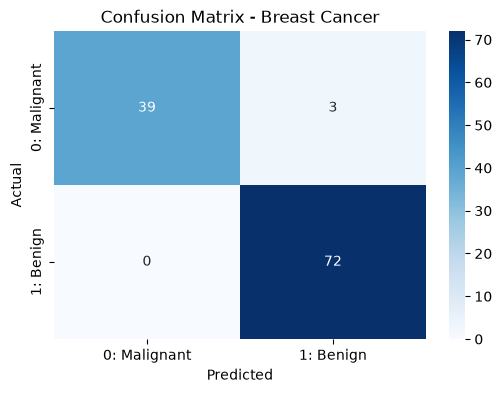


--- MANUAL CALCULATION FOR MALIGNANT (CLASS 0) ---
True Positives (TP): 39, False Negatives (FN): 3
False Positives (FP): 0, True Negatives (TN): 72
Manual Precision: 1.0000
Manual Recall: 0.9286
Manual F1-Score: 0.9630
Check these against the Classification Report row for '0 (Malignant)'.


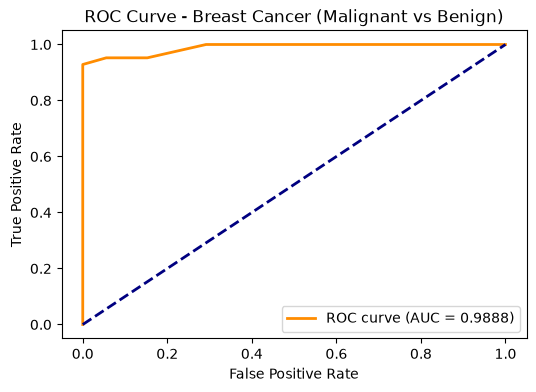

In [11]:
# ---------------------------------------------------------
# 9. Final Evaluation on the Test Set (Breast Cancer)
# ---------------------------------------------------------
print("--- 9. FINAL EVALUATION ON THE TEST SET (Breast Cancer) ---")
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, classification_report, 
                             confusion_matrix, roc_curve)

# 1. Şampiyon Modelin ve Verinin Hazırlanması
algo = best_model_bc['Algorithm']
rep = best_model_bc['Representation']
param = best_model_bc['Parameter']
X_test_final = X_test_scaled if rep == 'scaled' else X_test

if algo == 'Decision Tree': model_key = f"dt_{rep}_d{param}"
elif algo == 'KNN': model_key = f"knn_{rep}_k{param}"
else: model_key = f"gnb_{rep}_default"
champion_model = saved_models_seed42[model_key]

# 2. Tahminlerin Yapılması
y_test_pred = champion_model.predict(X_test_final)
y_test_prob = champion_model.predict_proba(X_test_final)[:, 0] # Sadece Sınıf 0 olasılığı
y_test_binary = (y_test == 0).astype(int) # Kötü huylu (0) = Pozitif (1)

# 3. Metriklerin Hesaplanması
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
test_rec = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)
test_roc = roc_auc_score(y_test_binary, y_test_prob)

# 4. Detaylı Sınıflandırma Raporu (Classification Report)
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_test_pred, target_names=['0 (Malignant)', '1 (Benign)']))

# 5. Hocanın İstediği Final Test Tablosu (DataFrame formatında)
test_results_df = pd.DataFrame([{
    'Dataset': 'Breast Cancer',
    'Configuration': f"{algo}_{rep}_{param}",
    'Evaluation_Seed': 42,
    'Val_Macro_F1_Mean': best_model_bc['Val_Macro_F1_mean'],
    'Val_Macro_F1_Std': best_model_bc['Val_Macro_F1_std'],
    'Test_Accuracy': test_acc,
    'Test_Macro_Precision': test_prec,
    'Test_Macro_Recall': test_rec,
    'Test_Macro_F1': test_f1,
    'Test_ROC_AUC': test_roc
}])
print("\n--- FINAL TEST TABLE ---")
display(test_results_df)

# 6. Karmaşıklık Matrisi (Confusion Matrix) Çizimi [0, 1] sırasıyla
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['0: Malignant', '1: Benign'], yticklabels=['0: Malignant', '1: Benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Breast Cancer')
plt.show()

# 7. Manuel Hesaplama (Malignant Sınıfı İçin)
# Orijinal sınıflarda 0=Malignant, 1=Benign. Matriste: Satır 0 = Gerçek Malignant, Sütun 0 = Tahmin Malignant
TP = cm[0, 0] # Gerçek Malignant, Tahmin Malignant
FN = cm[0, 1] # Gerçek Malignant, Tahmin Benign
FP = cm[1, 0] # Gerçek Benign, Tahmin Malignant
TN = cm[1, 1] # Gerçek Benign, Tahmin Benign

manual_precision = TP / (TP + FP) if (TP + FP) > 0 else 0
manual_recall = TP / (TP + FN) if (TP + FN) > 0 else 0
manual_f1 = 2 * (manual_precision * manual_recall) / (manual_precision + manual_recall) if (manual_precision + manual_recall) > 0 else 0

print("\n--- MANUAL CALCULATION FOR MALIGNANT (CLASS 0) ---")
print(f"True Positives (TP): {TP}, False Negatives (FN): {FN}")
print(f"False Positives (FP): {FP}, True Negatives (TN): {TN}")
print(f"Manual Precision: {manual_precision:.4f}")
print(f"Manual Recall: {manual_recall:.4f}")
print(f"Manual F1-Score: {manual_f1:.4f}")
print("Check these against the Classification Report row for '0 (Malignant)'.")

# 8. ROC Eğrisi Çizimi
fpr, tpr, thresholds = roc_curve(y_test_binary, y_test_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {test_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Breast Cancer (Malignant vs Benign)')
plt.legend(loc="lower right")
plt.show()

We tested our champion model on the unseen test set. The final test scores are very close to our validation scores. This shows that our model learned the data successfully and did not memorize the training set.

The manual calculations for the malignant class perfectly match the classification report. If we lower the ROC decision threshold, we will catch more malignant cases (higher True Positive Rate), which decreases false negatives but increases false positives. The model made a few misclassifications (false negatives or false positives). A limitation of this evaluation is that we only tested on one small subset (Seed 42), which may not represent all future data.

# 10. K-Means Clustering

--- 10. K-MEANS CLUSTERING (Breast Cancer) ---

--- 10.1 K-Means Run Table (6 Fits) ---


,Dataset,Seed,Representation,Train_Inertia,Val_ARI,Val_Silhouette
0,Breast Cancer,42,unscaled,5.156538e+07,0.399462,0.638725
1,Breast Cancer,42,scaled,7.918810e+03,0.451557,0.285448
2,Breast Cancer,52,unscaled,4.919078e+07,0.612245,0.697473
3,Breast Cancer,52,scaled,8.003001e+03,0.558609,0.375031
4,Breast Cancer,62,unscaled,5.305649e+07,0.501339,0.695777
5,Breast Cancer,62,scaled,7.922515e+03,0.733598,0.275781



--- 10.1 K-Means Summary Table ---


,Representation,Train_Inertia_Mean,Val_ARI_Mean,Val_ARI_Std,Val_Silhouette_Mean,Val_Silhouette_Std,Valid_Silhouette_Counts
0,scaled,7.948109e+03,0.581255,0.142378,0.312086,0.054725,3
1,unscaled,5.127088e+07,0.504349,0.106423,0.677325,0.033440,3



--- 10.2 Contingency Table (Breast Cancer - UNSCALED) ---


Predicted Clusters,0,1
True Classes,,
0,14,28
1,72,0



--- 10.2 Contingency Table (Breast Cancer - SCALED) ---


Predicted Clusters,0,1
True Classes,,
0,5,37
1,69,3



--- 10.2 Final Test Evaluation Table ---


,Dataset,Representation,Seed,Cluster_Counts,Test_ARI,Test_Silhouette
0,Breast Cancer,unscaled,42,"{0: 86, 1: 28}",0.558488,0.711999
1,Breast Cancer,scaled,42,"{0: 74, 1: 40}",0.735381,0.325062


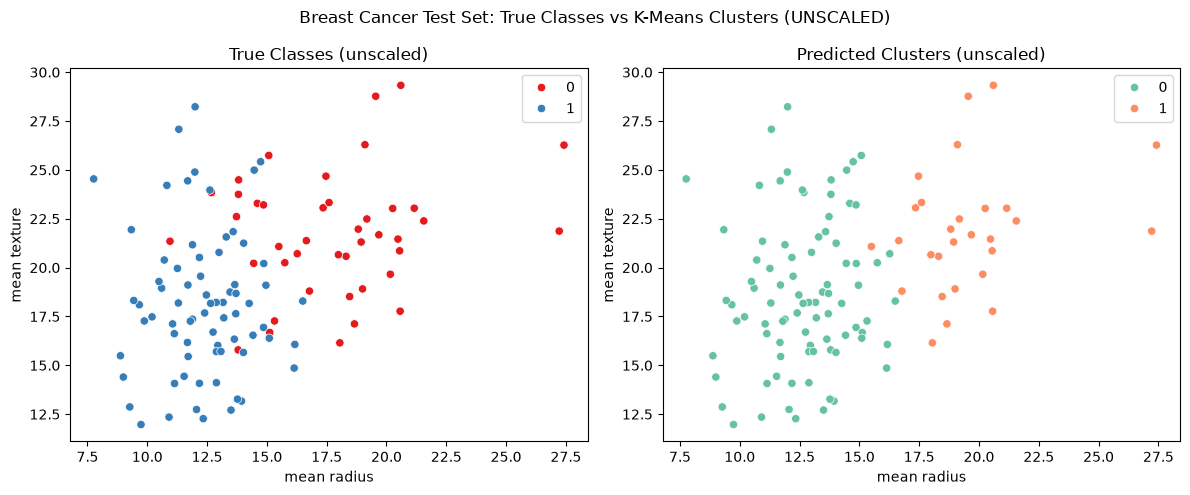

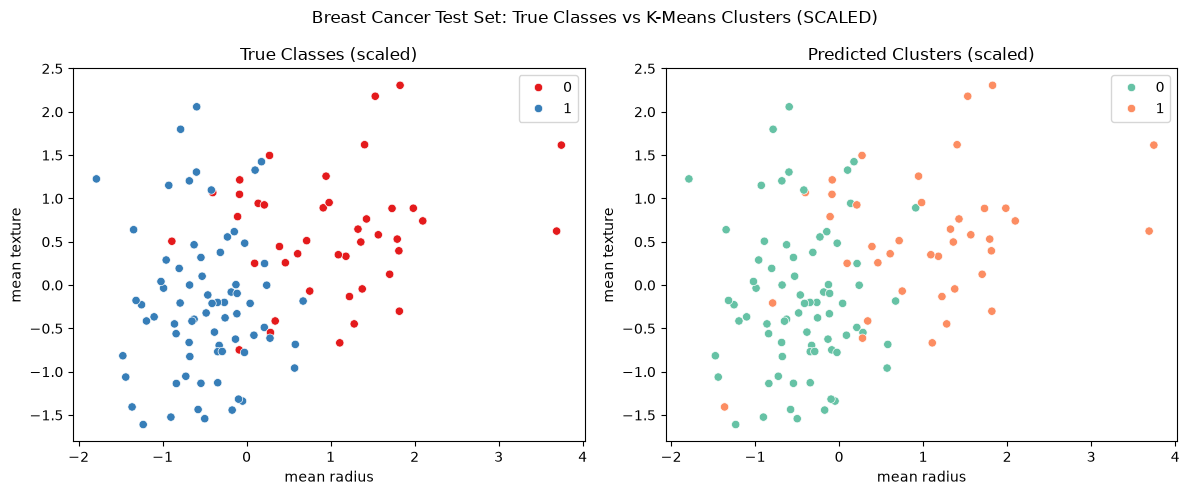

In [12]:
# ---------------------------------------------------------
# 10. K-Means Clustering (Breast Cancer)
# ---------------------------------------------------------
print("--- 10. K-MEANS CLUSTERING (Breast Cancer) ---")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

seeds = [42, 52, 62]
representations = ['unscaled', 'scaled']
kmeans_results = []
kmeans_models_seed42 = {}

# 10.1 Fit the clustering model
for seed in seeds:
    for rep in representations:
        # Dictionary yapısı kullanarak verileri çekiyoruz
        if rep == 'unscaled':
            X_tr, X_v = X_train_dict[seed], X_val_dict[seed]
        else:
            # 5. bölümde scaled verilerini attığın sözlük isimleri
            X_tr, X_v = X_train_scaled_dict[seed], X_val_scaled_dict[seed] 
            
        y_tr, y_v = y_train_dict[seed], y_val_dict[seed]
        
        # K-Means Modeli (n_clusters=2, hedef değişken Y verilmeyecek!)
        km = KMeans(n_clusters=2, random_state=seed, n_init=10)
        km.fit(X_tr) # Sadece X veriliyor!
        
        if seed == 42:
            kmeans_models_seed42[rep] = km # Test aşaması için Seed 42'yi sakla
            
        # Validation tahminleri ve Metrikler
        train_inertia = km.inertia_
        val_preds = km.predict(X_v)
        
        ari_val = adjusted_rand_score(y_v, val_preds)
        
        # Silhouette için en az 2 farklı küme olmalı
        if len(np.unique(val_preds)) > 1:
            sil_val = silhouette_score(X_v, val_preds)
        else:
            sil_val = np.nan
            
        kmeans_results.append({
            'Dataset': 'Breast Cancer', 'Seed': seed, 'Representation': rep,
            'Train_Inertia': train_inertia, 'Val_ARI': ari_val, 'Val_Silhouette': sil_val
        })

df_kmeans_runs = pd.DataFrame(kmeans_results)
print("\n--- 10.1 K-Means Run Table (6 Fits) ---")
display(df_kmeans_runs)

# Özet Tablo (Summary)
df_kmeans_summary = df_kmeans_runs.groupby('Representation').agg(
    Train_Inertia_Mean=('Train_Inertia', 'mean'),
    Val_ARI_Mean=('Val_ARI', 'mean'),
    Val_ARI_Std=('Val_ARI', lambda x: np.std(x, ddof=1)),
    Val_Silhouette_Mean=('Val_Silhouette', lambda x: x.mean(skipna=True)),
    Val_Silhouette_Std=('Val_Silhouette', lambda x: np.std(x.dropna(), ddof=1) if len(x.dropna())>1 else np.nan),
    Valid_Silhouette_Counts=('Val_Silhouette', 'count')
).reset_index()
print("\n--- 10.1 K-Means Summary Table ---")
display(df_kmeans_summary)

# 10.2 Final cluster evaluation on the fixed test sets (SADECE SEED 42)
test_eval_results = []

for rep in representations:
    km_test = kmeans_models_seed42[rep]
    # Test setlerini belirle
    X_t = X_test_scaled if rep == 'scaled' else X_test 
    
    test_preds = km_test.predict(X_t)
    
    # Küme sayımları
    cluster_counts = pd.Series(test_preds).value_counts().to_dict()
    
    # Çapraz Tablo (Contingency Table)
    contingency = pd.crosstab(y_test, test_preds, rownames=['True Classes'], colnames=['Predicted Clusters'])
    print(f"\n--- 10.2 Contingency Table (Breast Cancer - {rep.upper()}) ---")
    display(contingency)
    
    # Test Metrikleri
    ari_test = adjusted_rand_score(y_test, test_preds)
    sil_test = silhouette_score(X_t, test_preds) if len(np.unique(test_preds)) > 1 else np.nan
    
    test_eval_results.append({
        'Dataset': 'Breast Cancer', 'Representation': rep, 'Seed': 42,
        'Cluster_Counts': str(cluster_counts), 'Test_ARI': ari_test, 'Test_Silhouette': sil_test
    })

df_kmeans_test = pd.DataFrame(test_eval_results)
print("\n--- 10.2 Final Test Evaluation Table ---")
display(df_kmeans_test)

# 10.3 Visualise and interpret the clusters
# Görselleştirme için Seed 42 eğitim setinden 2 özellik seçiyoruz
X_train_seed42 = X_train_dict[42]
feature1_idx, feature2_idx = 0, 1 
feature1_name, feature2_name = X_train_seed42.columns[0], X_train_seed42.columns[1]

for rep in representations:
    km_test = kmeans_models_seed42[rep]
    X_t = X_test_scaled if rep == 'scaled' else X_test
    test_preds = km_test.predict(X_t)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Panel 1: True Classes
    sns.scatterplot(x=X_t.iloc[:, feature1_idx], y=X_t.iloc[:, feature2_idx], 
                    hue=y_test, palette='Set1', ax=axes[0])
    axes[0].set_title(f'True Classes ({rep})')
    axes[0].set_xlabel(feature1_name)
    axes[0].set_ylabel(feature2_name)
    
    # Panel 2: Predicted Clusters
    sns.scatterplot(x=X_t.iloc[:, feature1_idx], y=X_t.iloc[:, feature2_idx], 
                    hue=test_preds, palette='Set2', ax=axes[1])
    axes[1].set_title(f'Predicted Clusters ({rep})')
    axes[1].set_xlabel(feature1_name)
    axes[1].set_ylabel(feature2_name)
    
    plt.suptitle(f'Breast Cancer Test Set: True Classes vs K-Means Clusters ({rep.upper()})')
    plt.tight_layout()
    plt.show()

K-Means found groups in the data without seeing the real class labels. Scaling the data helped the model make much better groups. Our other models learned from the true answers, but K-Means only looked at the features.

# Export

In [14]:
import pandas as pd

# İsim senin kodundaki df_summary olarak düzeltildi
df_classifier_runs.to_csv('bc_class_runs.csv', index=False)
df_summary.to_csv('bc_class_summary.csv', index=False)

test_results_df.to_csv('bc_class_test.csv', index=False)
df_kmeans_runs.to_csv('bc_km_runs.csv', index=False)

df_kmeans_summary['Dataset'] = 'Breast Cancer' 
df_kmeans_summary.to_csv('bc_km_summary.csv', index=False)
df_kmeans_test.to_csv('bc_km_test.csv', index=False)

print("Kanser veri setinin CSV'leri başarıyla kaydedildi!")

Kanser veri setinin CSV'leri başarıyla kaydedildi!
